In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

In [2]:
# ---
# Load data
# ---

df = pd.read_excel(
    "data/combined_dataset.xlsx",
    sheet_name="Dataset",
)

# Preserve the original analysis filter
df = df.dropna(
    subset=["Lifespan"],
)


# ---
# Configuration
# ---

commissioning_col = "Start Year"
retirement_col = "Retired Year"
technology_col = "Technology"
capacity_col = "Capacity (MW)"

cutoff_year = 2025


# ---
# Technology groups
# ---

tech_groups = {
    "Fossil fuels": [
        "Coal",
        "Natural Gas",
        "Oil",
    ],
    "Core transition technologies": [
        "Solar PV",
        "Wind Onshore",
        "Wind Offshore",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
        "Solar Thermal",
    ],
}

technology_order = [
    tech
    for group in tech_groups.values()
    for tech in group
]


# ---
# Prepare shared plotting data
# ---

df_plot = df.copy()

for column in [
    commissioning_col,
    retirement_col,
    capacity_col,
]:
    df_plot[column] = pd.to_numeric(
        df_plot[column],
        errors="coerce",
    )

df_plot = df_plot.dropna(
    subset=[
        commissioning_col,
        technology_col,
        capacity_col,
    ]
).copy()

df_plot = df_plot[
    (df_plot[capacity_col] > 0)
    & (df_plot[commissioning_col] <= cutoff_year)
].copy()

# Convert MW to GW
df_plot["Capacity_GW"] = (
    df_plot[capacity_col]
    / 1000
)


In [3]:
# ---
# SI Figure 4
# ---

# Annual commissioned and retired capacity by technology
# Panel a: commissioned capacity
# Panel b: retired capacity
# Capacity shown in GW


# ---
# Colours
# ---

tech_colors = {
    "Coal": "#5A5A5A",
    "Natural Gas": "#8C8C8C",
    "Oil": "#B0B0B0",
    "Solar PV": "#D9B642",
    "Wind Onshore": "#4F9AB8",
    "Wind Offshore": "#3F708F",
    "Nuclear": "#72AAA4",
    "Bioenergy": "#7BAF7B",
    "Geothermal": "#B94745",
    "Hydropower": "#6A8FBF",
    "Solar Thermal": "#D98B82",
}


# ---
# Style
# ---

FONT_BASE = 10.0
FONT_TICKS = 10.0
FONT_PANEL = 11.0
FONT_TITLE = 11.0
FONT_AXIS_LABEL = 11.5
FONT_LEGEND = 10.0

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.75,
        "axes.labelsize": FONT_AXIS_LABEL,
        "axes.titlesize": FONT_TITLE,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TICKS,
        "legend.fontsize": FONT_LEGEND,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)

COLOR_TEXT = "#222222"
COLOR_GRID = "#BFBFBF"
COLOR_AXIS = "#444444"
COLOR_BACKGROUND = "white"
ZERO_LINE_COLOUR = "#222222"


# ---
# Commissioned capacity
# ---

df_commissioned = (
    df_plot.groupby(
        [
            commissioning_col,
            technology_col,
        ],
        as_index=False,
    )["Capacity_GW"]
    .sum()
    .rename(
        columns={
            commissioning_col: "Year",
            "Capacity_GW": "Capacity",
        }
    )
)

df_commissioned["Year"] = (
    df_commissioned["Year"]
    .astype(int)
)

df_commissioned = df_commissioned[
    df_commissioned["Year"] <= cutoff_year
]


# ---
# Retired capacity
# ---

df_retired = (
    df_plot.dropna(
        subset=[retirement_col],
    )
    .query(
        f"`{retirement_col}` <= @cutoff_year"
    )
    .groupby(
        [
            retirement_col,
            technology_col,
        ],
        as_index=False,
    )["Capacity_GW"]
    .sum()
    .rename(
        columns={
            retirement_col: "Year",
            "Capacity_GW": "Capacity",
        }
    )
)

df_retired["Capacity"] = -df_retired["Capacity"]

df_retired["Year"] = (
    df_retired["Year"]
    .astype(int)
)


# ---
# Pivot tables
# ---

df_commissioned_pivot = (
    df_commissioned.pivot_table(
        index="Year",
        columns=technology_col,
        values="Capacity",
        aggfunc="sum",
        fill_value=0,
    )
    .sort_index()
)

df_retired_pivot = (
    df_retired.pivot_table(
        index="Year",
        columns=technology_col,
        values="Capacity",
        aggfunc="sum",
        fill_value=0,
    )
    .sort_index()
)


# ---
# Technology order
# ---

available_techs = sorted(
    set(df_commissioned_pivot.columns).union(
        df_retired_pivot.columns
    )
)

ordered_techs = [
    tech
    for tech in technology_order
    if tech in available_techs
]

# Retain any technologies outside the predefined groups
ordered_techs.extend(
    [
        tech
        for tech in available_techs
        if tech not in ordered_techs
    ]
)

df_commissioned_pivot = df_commissioned_pivot.reindex(
    columns=ordered_techs,
    fill_value=0,
)

df_retired_pivot = df_retired_pivot.reindex(
    columns=ordered_techs,
    fill_value=0,
)


# ---
# Common year range
# ---

year_min = int(
    min(
        df_commissioned_pivot.index.min(),
        (
            df_retired_pivot.index.min()
            if len(df_retired_pivot) > 0
            else df_commissioned_pivot.index.min()
        ),
    )
)

year_max = cutoff_year

x_tick_start = int(
    np.floor(year_min / 20)
    * 20
)

x_ticks = np.arange(
    x_tick_start,
    year_max + 1,
    20,
)



In [4]:
# ---
# Plotting helpers
# ---

# Plot one stacked annual-capacity panel.
def plot_stacked_capacity_panel(
    ax,
    pivot_data,
    ylabel,
    title,
    panel_label,
):
    bottom = np.zeros(
        len(pivot_data)
    )

    for tech in ordered_techs:
        values = pivot_data[
            tech
        ].to_numpy()

        ax.bar(
            pivot_data.index,
            values,
            bottom=bottom,
            label=tech,
            color=tech_colors.get(
                tech,
                "#CCCCCC",
            ),
            width=0.9,
            edgecolor="none",
            zorder=3,
        )

        bottom += values

    ax.axhline(
        0,
        color=ZERO_LINE_COLOUR,
        linewidth=0.85,
        zorder=4,
    )

    ax.set_ylabel(
        ylabel,
        fontsize=FONT_AXIS_LABEL,
        fontweight="normal",
        color=COLOR_TEXT,
    )

    ax.set_title(
        title,
        fontsize=FONT_TITLE,
        fontweight="bold",
        color=COLOR_TEXT,
        pad=7,
    )

    ax.text(
        -0.055,
        1.08,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_PANEL,
        fontweight="bold",
        color=COLOR_TEXT,
    )


# Apply common axis styling.
def style_capacity_axis(ax):
    ax.set_xlim(
        year_min,
        year_max + 1,
    )

    ax.set_xticks(
        x_ticks,
    )

    ax.grid(
        axis="y",
        linestyle="-",
        linewidth=0.45,
        alpha=0.30,
        color=COLOR_GRID,
        zorder=0,
    )

    ax.grid(
        axis="x",
        visible=False,
    )

    ax.set_axisbelow(
        True,
    )

    for spine in [
        "top",
        "right",
    ]:
        ax.spines[spine].set_visible(
            False,
        )

    for spine in [
        "left",
        "bottom",
    ]:
        ax.spines[spine].set_linewidth(
            0.75,
        )
        ax.spines[spine].set_color(
            COLOR_AXIS,
        )

    ax.tick_params(
        axis="both",
        direction="out",
        length=3.2,
        width=0.75,
        pad=3,
        labelsize=FONT_TICKS,
        colors=COLOR_TEXT,
    )


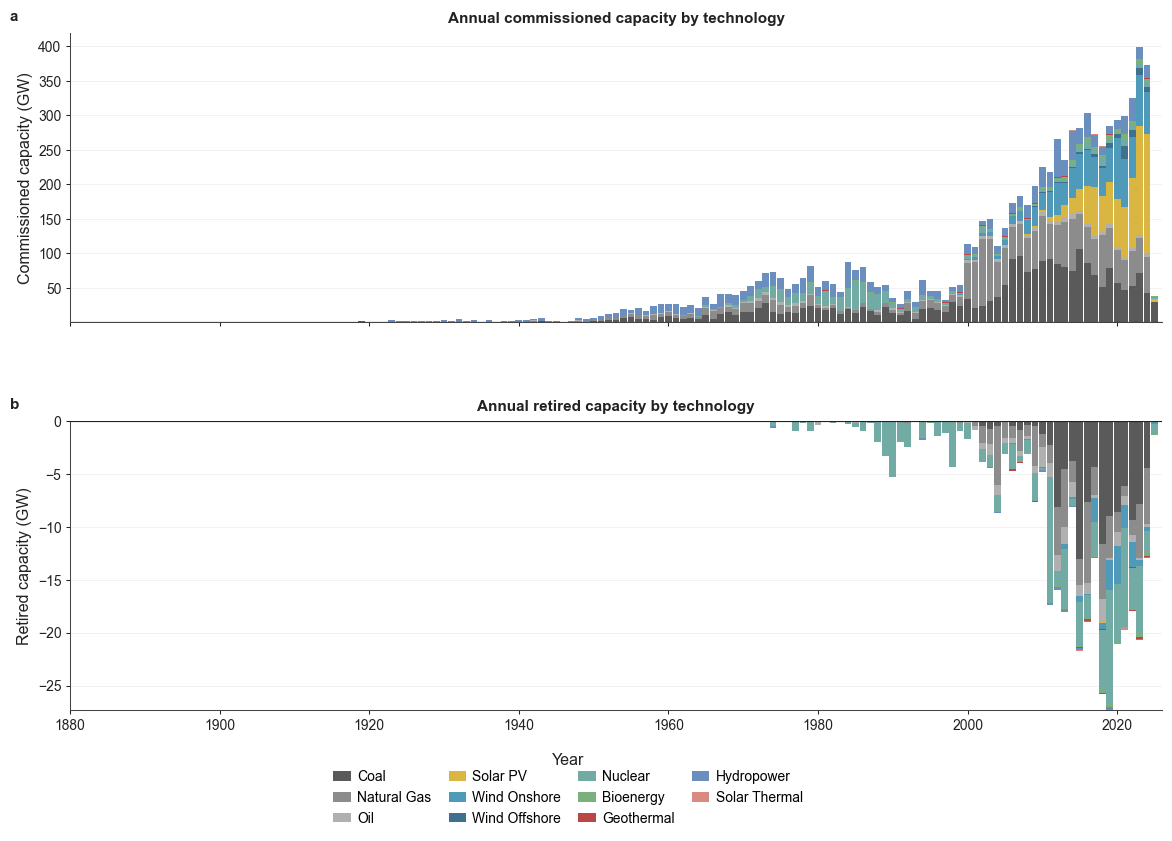

In [5]:
# ---
# Figure
# ---

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12.0, 8.8),
    sharex=True,
)

fig.patch.set_facecolor(
    COLOR_BACKGROUND,
)

for ax in axes:
    ax.set_facecolor(
        COLOR_BACKGROUND,
    )

plot_stacked_capacity_panel(
    axes[0],
    df_commissioned_pivot,
    "Commissioned capacity (GW)",
    "Annual commissioned capacity by technology",
    "a",
)

plot_stacked_capacity_panel(
    axes[1],
    df_retired_pivot,
    "Retired capacity (GW)",
    "Annual retired capacity by technology",
    "b",
)

for ax in axes:
    style_capacity_axis(
        ax,
    )


# ---
# Shared labels and legend
# ---

fig.supxlabel(
    "Year",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    y=0.105,
    color=COLOR_TEXT,
)

legend_elements = [
    Patch(
        facecolor=tech_colors.get(
            tech,
            "#CCCCCC",
        ),
        edgecolor="none",
        label=tech,
    )
    for tech in ordered_techs
]

fig.legend(
    handles=legend_elements,
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        0.025,
    ),
    ncol=4,
    fontsize=FONT_LEGEND,
    columnspacing=1.25,
    handlelength=1.25,
    handletextpad=0.45,
)


# ---
# Layout
# ---

fig.subplots_adjust(
    left=0.085,
    right=0.995,
    top=0.94,
    bottom=0.17,
    hspace=0.34,
)


# ---
# Save
# ---
plt.savefig(
    "figures/si/figure-4.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)
plt.savefig(
    "figures/si/figure-4.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.show()


In [6]:
# ---
# SI Figure 5
# ---

# Capacity additions and retirements by technology
# Positive bars = capacity added by deployment year
# Negative bars = capacity retired by retirement year
# Bar colour = original deployment year
#
# Negative retirement bars are visually scaled to improve visibility.
# Y-axis tick labels report true, unscaled capacity values.


# ---
# Configuration
# ---

# Visual scaling for negative retirement bars.
# Tick labels are corrected back to true GW values.
RETIREMENT_DISPLAY_SCALE = 5


# ---
# Technology order
# ---

available_techs = set(
    df_plot[technology_col]
    .dropna()
    .unique()
)

ordered_groups = {
    group_name: [
        tech
        for tech in group_techs
        if tech in available_techs
    ]
    for group_name, group_techs in tech_groups.items()
}

# Retain technologies outside the predefined groups
grouped_techs = {
    tech
    for group_techs in ordered_groups.values()
    for tech in group_techs
}

ungrouped_techs = sorted(
    available_techs
    - grouped_techs
)

if ungrouped_techs:
    ordered_groups[
        "Other technologies"
    ] = ungrouped_techs


# ---
# Colour map based on deployment year
# ---

start_year_min = 1950
start_year_max = cutoff_year

norm = mpl.colors.Normalize(
    vmin=start_year_min,
    vmax=start_year_max,
)

cmap = mpl.cm.cividis


# ---
# Style
# ---

FONT_BASE = 10.0
FONT_TICKS = 10.0
FONT_TITLE = 10.5
FONT_PANEL = 10.5
FONT_GROUP_HEADER = 11.0
FONT_INFO = 10.0
FONT_AXIS_LABEL = 11.5
FONT_COLORBAR = 10.0
FONT_NOTE = 10.0

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.75,
        "axes.labelsize": FONT_AXIS_LABEL,
        "axes.titlesize": FONT_TITLE,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TICKS,
        "legend.fontsize": 10.0,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)

TEXT_COLOUR = "#222222"
SECONDARY_TEXT_COLOUR = "#555555"
AXIS_COLOUR = "#444444"
GROUP_LINE_COLOUR = "#777777"
GRID_COLOUR = "#BFBFBF"
ZERO_LINE_COLOUR = "#222222"
COLOR_BACKGROUND = "white"


In [7]:
# ---
# Plotting helpers
# ---

# Format scaled retirement capacity while preserving true GW labels.
def scaled_capacity_formatter(y, _):
    value = (
        y / RETIREMENT_DISPLAY_SCALE
        if y < 0
        else y
    )

    if abs(value) >= 10:
        return f"{value:.0f}"

    return f"{value:.1f}"


# Add a group heading and separator line.
def add_group_header(ax, title):
    ax.axis(
        "off"
    )

    ax.text(
        0.0,
        0.65,
        title,
        transform=ax.transAxes,
        ha="left",
        va="center",
        fontsize=FONT_GROUP_HEADER,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    ax.plot(
        [
            0.0,
            1.0,
        ],
        [
            0.15,
            0.15,
        ],
        transform=ax.transAxes,
        color=GROUP_LINE_COLOUR,
        linewidth=0.75,
        clip_on=False,
    )


# Return GridSpec positions for one group row.
def get_panel_positions(
    row_index,
    n_panels,
):
    if n_panels == 1:
        return [
            (
                row_index,
                slice(0, 12),
            )
        ]

    if n_panels == 2:
        return [
            (
                row_index,
                slice(0, 6),
            ),
            (
                row_index,
                slice(6, 12),
            ),
        ]

    if n_panels == 3:
        return [
            (
                row_index,
                slice(0, 4),
            ),
            (
                row_index,
                slice(4, 8),
            ),
            (
                row_index,
                slice(8, 12),
            ),
        ]

    if n_panels == 4:
        return [
            (
                row_index,
                slice(0, 3),
            ),
            (
                row_index,
                slice(3, 6),
            ),
            (
                row_index,
                slice(6, 9),
            ),
            (
                row_index,
                slice(9, 12),
            ),
        ]

    positions = []
    width = 12 / n_panels

    for index in range(n_panels):
        start = int(
            round(
                index * width
            )
        )

        end = int(
            round(
                (index + 1) * width
            )
        )

        positions.append(
            (
                row_index,
                slice(
                    start,
                    end,
                ),
            )
        )

    return positions


# Plot additions and retirements for one technology.
def plot_capacity_panel(
    ax,
    tech,
    panel_label,
):
    subset = df_plot[
        df_plot[technology_col] == tech
    ].copy()

    if subset.empty:
        ax.axis(
            "off"
        )
        return

    # Active and retired subsets
    active_subset = subset[
        subset[retirement_col].isna()
        | (subset[retirement_col] > cutoff_year)
    ].copy()

    retired_subset = subset[
        subset[retirement_col].notna()
        & (subset[retirement_col] <= cutoff_year)
    ].copy()

    n_active = len(
        active_subset
    )

    active_capacity_gw = active_subset[
        "Capacity_GW"
    ].sum()

    n_retired = len(
        retired_subset
    )

    retired_capacity_gw = retired_subset[
        "Capacity_GW"
    ].sum()

    # Positive deployment bars grouped by start year
    deployed = (
        subset.groupby(
            commissioning_col,
            as_index=False,
        )["Capacity_GW"]
        .sum()
        .rename(
            columns={
                commissioning_col: "Year",
                "Capacity_GW": "Capacity",
            }
        )
    )

    for _, row in deployed.iterrows():
        year = int(
            row["Year"]
        )

        ax.bar(
            year,
            row["Capacity"],
            color=cmap(
                norm(year)
            ),
            width=0.9,
            edgecolor="none",
            zorder=3,
        )

    # Negative retirement bars grouped by retirement and deployment year
    retired = (
        retired_subset.groupby(
            [
                retirement_col,
                commissioning_col,
            ],
            as_index=False,
        )["Capacity_GW"]
        .sum()
        .rename(
            columns={
                retirement_col: "Retired_Year",
                commissioning_col: "Deployment_Year",
                "Capacity_GW": "Capacity",
            }
        )
    )

    negative_bottoms = {}

    for _, row in retired.iterrows():
        retired_year = int(
            row["Retired_Year"]
        )

        deployment_year = int(
            row["Deployment_Year"]
        )

        capacity_display = (
            -row["Capacity"]
            * RETIREMENT_DISPLAY_SCALE
        )

        bottom = negative_bottoms.get(
            retired_year,
            0,
        )

        ax.bar(
            retired_year,
            capacity_display,
            bottom=bottom,
            color=cmap(
                norm(deployment_year)
            ),
            width=0.9,
            edgecolor="none",
            zorder=3,
        )

        negative_bottoms[
            retired_year
        ] = (
            bottom
            + capacity_display
        )

    # Zero line
    ax.axhline(
        0,
        color=ZERO_LINE_COLOUR,
        linewidth=0.85,
        zorder=4,
    )

    # Active summary
    ax.text(
        0.03,
        0.94,
        (
            f"Active: n = {n_active:,} | "
            f"{active_capacity_gw:.2f} GW"
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_INFO,
        fontweight="normal",
        color=SECONDARY_TEXT_COLOUR,
        zorder=6,
    )

    # Retired summary
    retired_label_y = (
        -0.01
        if tech == "Hydropower"
        else 0.03
    )

    ax.text(
        0.03,
        retired_label_y,
        (
            f"Retired: n = {n_retired:,} | "
            f"{retired_capacity_gw:.2f} GW"
        ),
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=FONT_INFO,
        fontweight="normal",
        color=SECONDARY_TEXT_COLOUR,
        zorder=6,
    )

    # Panel label
    ax.text(
        -0.13,
        1.12,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_PANEL,
        fontweight="bold",
        color=TEXT_COLOUR,
    )

    # Technology title
    ax.set_title(
        tech,
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=6,
        color=TEXT_COLOUR,
    )

    # Axes
    ax.set_xlim(
        start_year_min,
        cutoff_year + 1,
    )

    ax.set_ylabel(
        ""
    )

    x_tick_start = int(
        np.floor(
            start_year_min / 20
        )
        * 20
    )

    ax.set_xticks(
        np.arange(
            x_tick_start,
            cutoff_year + 1,
            20,
        )
    )

    ax.yaxis.set_major_formatter(
        FuncFormatter(
            scaled_capacity_formatter
        )
    )

    # Grid
    ax.grid(
        axis="y",
        linestyle="-",
        linewidth=0.45,
        alpha=0.30,
        color=GRID_COLOUR,
        zorder=0,
    )

    ax.grid(
        axis="x",
        visible=False,
    )

    ax.set_axisbelow(
        True,
    )

    # Spines
    for spine in [
        "top",
        "right",
    ]:
        ax.spines[spine].set_visible(
            False,
        )

    for spine in [
        "left",
        "bottom",
    ]:
        ax.spines[spine].set_linewidth(
            0.75,
        )
        ax.spines[spine].set_color(
            AXIS_COLOUR,
        )

    # Ticks
    ax.tick_params(
        axis="both",
        direction="out",
        length=3.2,
        width=0.75,
        pad=3,
        labelsize=FONT_TICKS,
        colors=TEXT_COLOUR,
    )


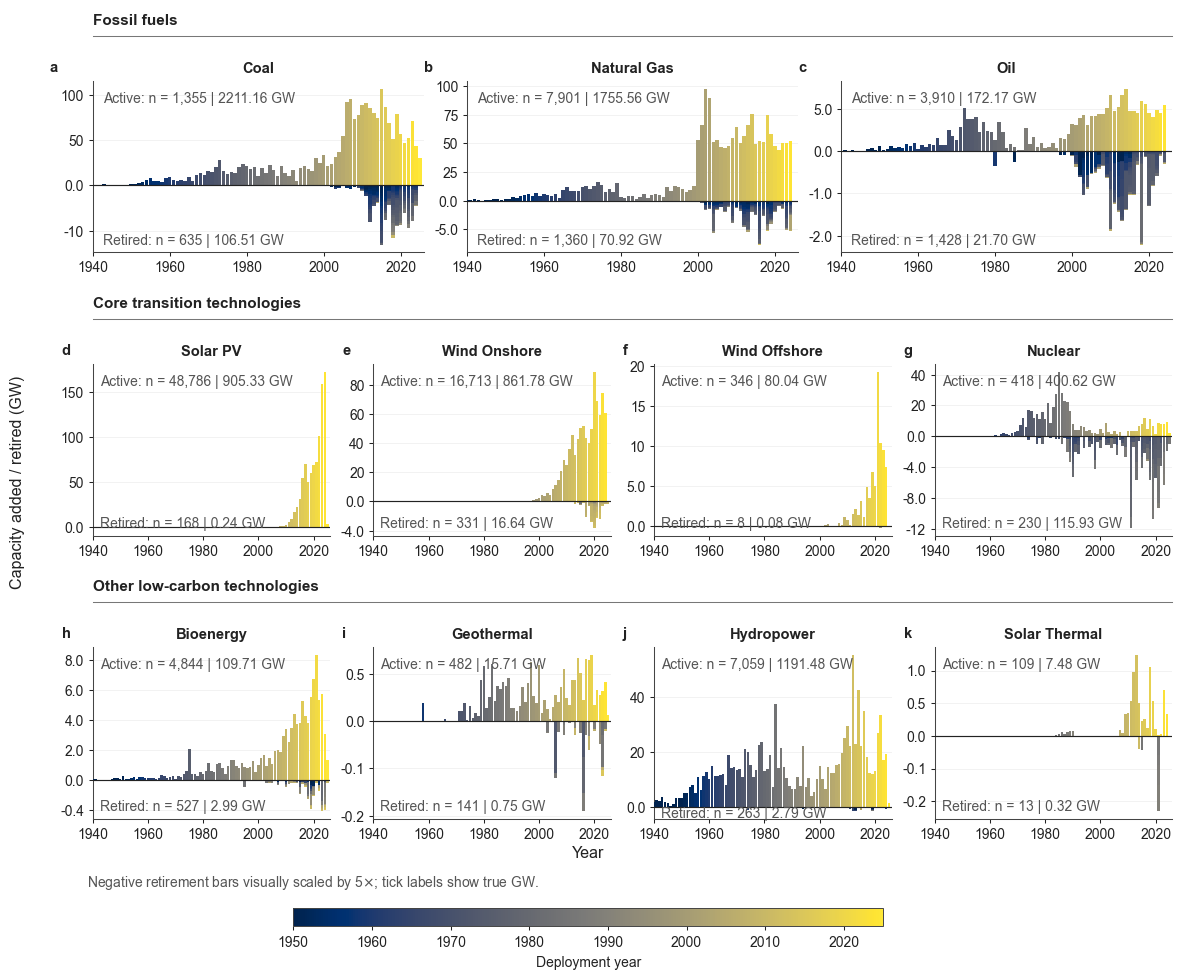

In [8]:
# ---
# Build figure grid
# ---

nonempty_groups = {
    group_name: techs
    for group_name, techs in ordered_groups.items()
    if techs
}

group_names = list(
    nonempty_groups.keys()
)

n_groups = len(
    group_names
)

height_ratios = [
    ratio
    for _ in range(n_groups)
    for ratio in (
        0.18,
        1.0,
    )
]

fig = plt.figure(
    figsize=(
        11.8,
        3.25 * n_groups,
    ),
    facecolor=COLOR_BACKGROUND,
)

gs = GridSpec(
    nrows=n_groups * 2,
    ncols=12,
    figure=fig,
    height_ratios=height_ratios,
    hspace=0.40,
    wspace=0.85,
)


# ---
# Create panels
# ---

panel_counter = 0

for group_index, group_name in enumerate(
    group_names
):
    header_row = group_index * 2
    panel_row = header_row + 1

    ax_header = fig.add_subplot(
        gs[
            header_row,
            :,
        ]
    )

    add_group_header(
        ax_header,
        group_name,
    )

    tech_list = nonempty_groups[
        group_name
    ]

    positions = get_panel_positions(
        panel_row,
        len(tech_list),
    )

    for tech, (
        row_index,
        col_slice,
    ) in zip(
        tech_list,
        positions,
    ):
        ax = fig.add_subplot(
            gs[
                row_index,
                col_slice,
            ]
        )

        ax.set_facecolor(
            COLOR_BACKGROUND,
        )

        plot_capacity_panel(
            ax=ax,
            tech=tech,
            panel_label=chr(
                97 + panel_counter
            ),
        )

        panel_counter += 1


# ---
# Shared labels
# ---

fig.supylabel(
    "Capacity added / retired (GW)",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    x=0.010,
    color=TEXT_COLOUR,
)

fig.supxlabel(
    "Year",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    y=0.112,
    color=TEXT_COLOUR,
)


# ---
# Retirement scaling note
# ---

fig.text(
    0.075,
    0.090,
    (
        "Negative retirement bars visually scaled by "
        rf"{RETIREMENT_DISPLAY_SCALE}$\times$; "
        "tick labels show true GW."
    ),
    ha="left",
    va="center",
    fontsize=FONT_NOTE,
    color=SECONDARY_TEXT_COLOUR,
)


# ---
# Deployment-year colourbar
# ---

sm = mpl.cm.ScalarMappable(
    cmap=cmap,
    norm=norm,
)

sm.set_array(
    []
)

cbar_ax = fig.add_axes(
    [
        0.25,
        0.045,
        0.50,
        0.018,
    ]
)

cbar = fig.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal",
)

cbar.set_label(
    "Deployment year",
    fontsize=FONT_COLORBAR,
    color=TEXT_COLOUR,
    labelpad=5,
)

cbar.ax.tick_params(
    labelsize=FONT_TICKS,
    length=3.0,
    width=0.75,
    colors=TEXT_COLOUR,
)

cbar.outline.set_linewidth(
    0.70,
)

cbar.outline.set_edgecolor(
    AXIS_COLOUR,
)


# ---
# Layout
# ---

fig.subplots_adjust(
    left=0.080,
    right=0.995,
    bottom=0.155,
    top=0.985,
)


# ---
# Save
# ---
plt.savefig(
    "figures/si/figure-5.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    "figures/si/figure-5.pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.show()
